<a href="https://colab.research.google.com/github/furalmiqbadi/PembelajaranMesin_01_AbdulGhofurAlmiqbadi/blob/main/JS08/JS08_Tugas01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Langkah 0 - Persiapan Lingkungan

In [ ]:
# Import Library
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.preprocessing import StandardScaler
import scipy.cluster.hierarchy as sch

## Langkah 1 - Load dan Inspeksi Dataset

In [ ]:
# Load dataset
df = pd.read_csv('/content/CC_Customer_Dataset.csv')

# Inspeksi data
print("Informasi Dataset:")
df.info()
print("\nLima data pertama:")
df.head()

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB

Lima data pertama:


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


## Langkah 2 - Pra-pemrosesan Data

In [ ]:
# Simpan kolom asli untuk visualisasi nanti
df_plot = df[['Avg_Credit_Limit', 'Total_Credit_Cards']].copy()

# Hapus kolom identifier yang tidak relevan untuk clustering
X_df = df.drop(columns=['Sl_No', 'Customer Key'])

# Pastikan hanya kolom numerik yang digunakan
X_df = X_df.select_dtypes(include=[np.number])

# Handling missing values (jika ada, diisi dengan median)
X_df = X_df.fillna(X_df.median())

# Scaling fitur agar semua variabel memiliki bobot yang sama (mean=0, variance=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_df)

print(f"Jumlah fitur yang digunakan untuk clustering: {X_df.shape[1]}")
print(f"Fitur tersebut adalah: {list(X_df.columns)}")

Jumlah fitur yang digunakan untuk clustering: 5
Fitur tersebut adalah: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


## Langkah 3 - Visualisasi Dendrogram

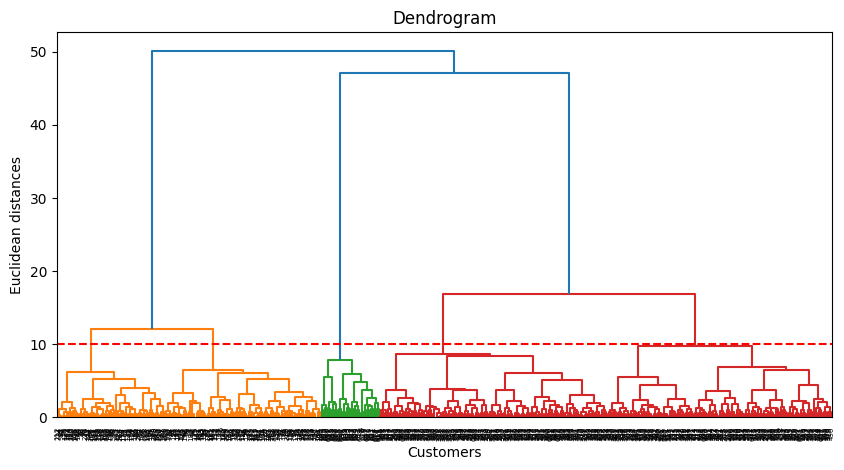

In [ ]:
# Build dendrogram
plt.figure(figsize=(10, 5))
dendrogram = sch.dendrogram(sch.linkage(X_scaled, method='ward'))
plt.title('Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Euclidean distances')
plt.axhline(y=10, color='r', linestyle='--') # Garis bantu threshold (bisa disesuaikan)
plt.show()

## Langkah 4 - Membuat Model Agglomerative Clustering

In [ ]:
# Build Cluster using Agglomerative Method
n_clusters = 3  # <-- UBAH NILAI INI SESUAI HASIL DENDROGRAM KAMU
hc = AgglomerativeClustering(n_clusters=n_clusters, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X_scaled)

# Tambahkan hasil cluster ke dataframe asli untuk keperluan visualisasi
df['Cluster'] = y_hc
print(f"Model berhasil dibuat dengan {n_clusters} cluster.")
print("\nDistribusi jumlah nasabah per cluster:")
print(df['Cluster'].value_counts().sort_index())

Model berhasil dibuat dengan 3 cluster.

Distribusi jumlah nasabah per cluster:
Cluster
0    385
1    225
2     50
Name: count, dtype: int64


## Langkah 5 - Visualisasi Cluster

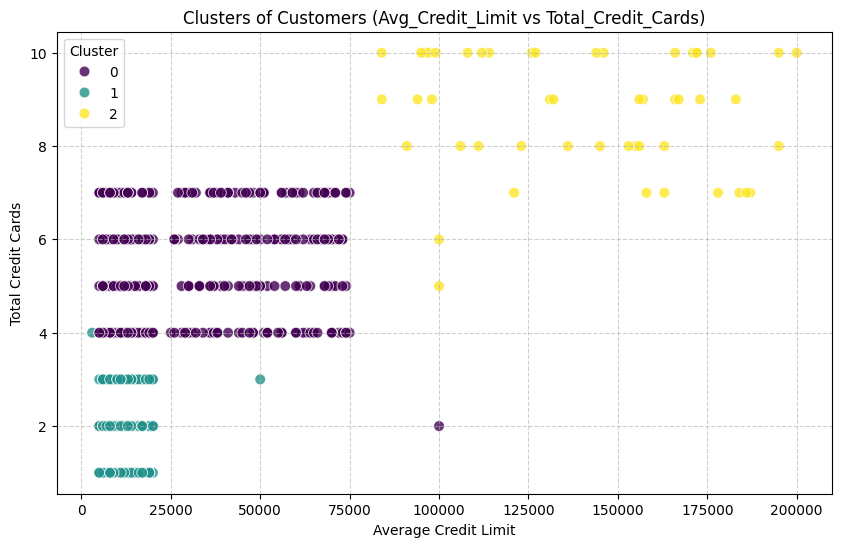

In [ ]:
# Visualisasi Cluster berdasarkan Avg_Credit_Limit dan Total_Credit_Cards
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards',
    hue='Cluster',
    palette='viridis',
    s=60,
    alpha=0.8
)

plt.title('Clusters of Customers (Avg_Credit_Limit vs Total_Credit_Cards)')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## Langkah 6 - Evaluasi Model


In [ ]:
# Menghitung Silhouette Score
sil_score = silhouette_score(X_scaled, y_hc)
print(f"Silhouette Score: {sil_score:.4f}")
print("-> Nilai mendekati 1 menunjukkan cluster yang padat dan terpisah dengan baik.\n")

# Menghitung Davies-Bouldin Index (DBI)
dbi_score = davies_bouldin_score(X_scaled, y_hc)
print(f"Davies-Bouldin Index: {dbi_score:.4f}")
print("-> Nilai yang lebih rendah (mendekati 0) menunjukkan cluster yang lebih baik dan terpisah jelas.")

Silhouette Score: 0.5148
-> Nilai mendekati 1 menunjukkan cluster yang padat dan terpisah dengan baik.

Davies-Bouldin Index: 0.6810
-> Nilai yang lebih rendah (mendekati 0) menunjukkan cluster yang lebih baik dan terpisah jelas.
